In [1]:
import cv2
import numpy as np
import pandas as pd
import pickle
import os
from ultralytics import YOLO

In [2]:
MODEL_PATH = r"C:\Users\DELL\OneDrive\Desktop\Final\yolov8n.pt"

model = YOLO(MODEL_PATH)

print("YOLO model loaded")

YOLO model loaded


In [4]:
VEHICLE_CLASSES = [2, 3, 5, 7]

CLASS_NAMES = {
    1: "man",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}

print(CLASS_NAMES)

{1: 'man', 2: 'car', 3: 'motorcycle', 5: 'bus', 7: 'truck'}


In [5]:
VIDEO_PATH = r"C:\Users\DELL\OneDrive\Desktop\Final\Trafficvedio.mp4"

cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("FPS:", fps)
print("Frames:", frame_count)
print("Resolution:", width, "x", height)

cap.release()

FPS: 23.976023976023978
Frames: 660
Resolution: 1920 x 1080


In [6]:
cap = cv2.VideoCapture(VIDEO_PATH)

vehicle_positions = {}
vehicle_classes = {}

while True:

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        source=frame,
        classes=VEHICLE_CLASSES,
        persist=True,
        conf=0.5,
        verbose=False
    )

    result = results[0]

    if result.boxes.id is not None:

        ids = result.boxes.id.cpu().numpy()
        boxes = result.boxes.xyxy.cpu().numpy()
        classes = result.boxes.cls.cpu().numpy()

        for track_id, box, cls in zip(ids, boxes, classes):

            track_id = int(track_id)

            x1, y1, x2, y2 = box

            center_x = (x1 + x2) / 2
            center_y = (y1 + y2) / 2

            if track_id not in vehicle_positions:
                vehicle_positions[track_id] = []

            vehicle_positions[track_id].append(
                (center_x, center_y)
            )

            vehicle_classes[track_id] = CLASS_NAMES[int(cls)]

cap.release()

print("Unique vehicles:", len(vehicle_positions))

Unique vehicles: 88


In [7]:
with open(
    r"C:\Users\DELL\OneDrive\Desktop\Final\vehicle_positions.pkl",
    "wb"
) as f:

    pickle.dump(vehicle_positions, f)

print("Vehicle positions saved")

Vehicle positions saved


In [8]:
with open(
    r"C:\Users\DELL\OneDrive\Desktop\Final\vehicle_classes.pkl",
    "wb"
) as f:

    pickle.dump(vehicle_classes, f)

print("Vehicle classes saved")

Vehicle classes saved


In [9]:
from ultralytics import YOLO
import cv2
import numpy as np
import pandas as pd
import os
import time

MODEL_PATH = r"C:\Users\DELL\OneDrive\Desktop\Final\yolov8n.pt"
VIDEO_PATH = r"C:\Users\DELL\OneDrive\Desktop\Final\Trafficvedio.mp4"

model = YOLO(MODEL_PATH)

print("YOLO model loaded successfully")

YOLO model loaded successfully


In [10]:
VEHICLE_CLASSES = [2, 3, 5, 7]

CLASS_NAMES = {
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}

print("Vehicle classes:", CLASS_NAMES)

Vehicle classes: {2: 'car', 3: 'motorcycle', 5: 'bus', 7: 'truck'}


In [13]:
import numpy as np
import cv2

ROAD_ROI = np.array([
    [190, 165],   # top-left
    [645, 165],   # top-right
    [745, 390],   # bottom-right
    [120, 390]    # bottom-left
], dtype=np.int32)

print("ROAD_ROI defined successfully")
print("ROI dtype:", ROAD_ROI.dtype)
print("ROI shape:", ROAD_ROI.shape)

ROAD_ROI defined successfully
ROI dtype: int32
ROI shape: (4, 2)


In [14]:
print("Current ROI:")
print(ROAD_ROI)
print("ROI dtype:", ROAD_ROI.dtype)

Current ROI:
[[190 165]
 [645 165]
 [745 390]
 [120 390]]
ROI dtype: int32


In [17]:
# ==========================================
# ROAD ROI - FULL MAIN ROAD AREA
# ==========================================

import numpy as np
import cv2
import matplotlib.pyplot as plt

ROAD_ROI = np.array([
    [80, 180],      # Top-left
    [1840, 180],    # Top-right
    [1920, 1080],   # Bottom-right
    [0, 1080]       # Bottom-left
], dtype=np.int32)

print("ROAD_ROI defined")
print("ROI dtype:", ROAD_ROI.dtype)
print("ROI shape:", ROAD_ROI.shape)

ROAD_ROI defined
ROI dtype: int32
ROI shape: (4, 2)


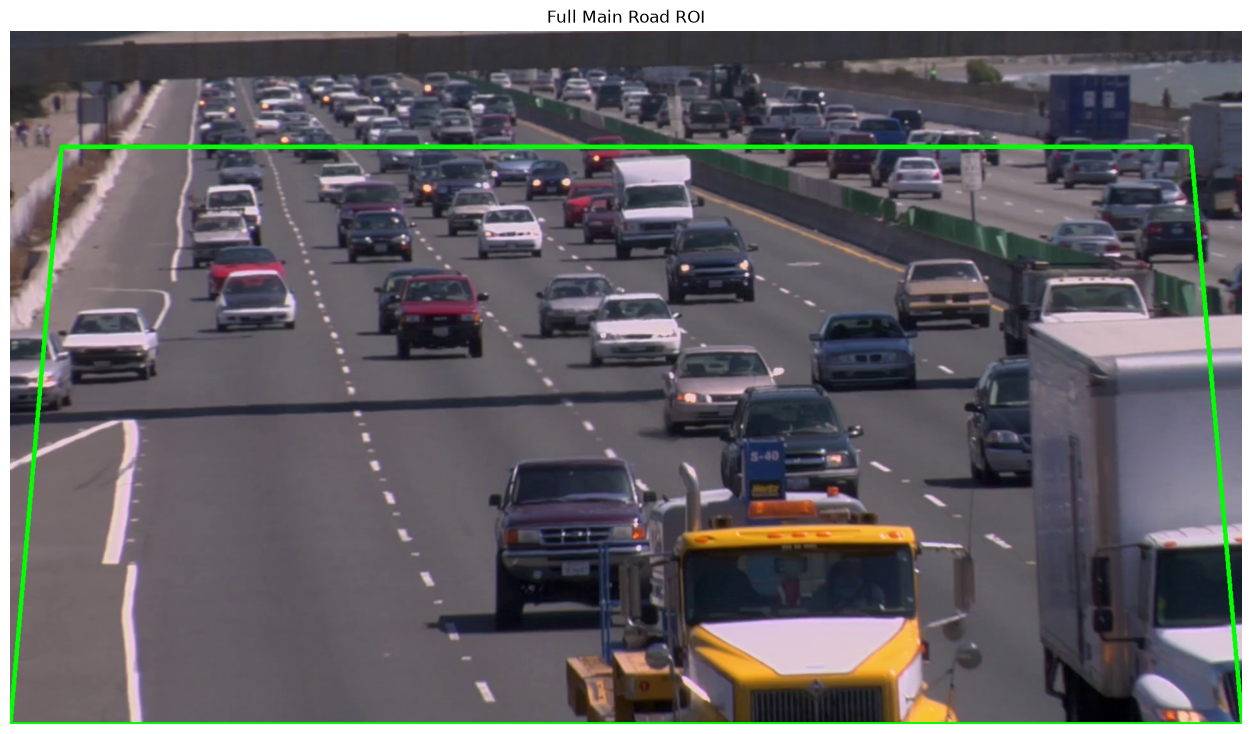

In [18]:
# ==========================================
# DISPLAY FULL ROAD ROI
# ==========================================

cap = cv2.VideoCapture(VIDEO_PATH)

ret, frame = cap.read()

cap.release()

if not ret:
    print("ERROR: Unable to read video")

else:

    roi_frame = frame.copy()

    cv2.polylines(
        roi_frame,
        [ROAD_ROI],
        isClosed=True,
        color=(0, 255, 0),
        thickness=6
    )

    plt.figure(figsize=(16, 9))

    plt.imshow(
        cv2.cvtColor(
            roi_frame,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title("Full Main Road ROI")
    plt.axis("off")
    plt.show()

In [19]:
ROAD_ROI = np.array([
    [100, 250],
    [1820, 250],
    [1920, 1080],
    [0, 1080]
], dtype=np.int32)

In [21]:
# ==========================================
# LOAD SAVED VEHICLE DATA
# ==========================================

import pickle
import pandas as pd
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt

PKL_PATH = r"C:\Users\DELL\OneDrive\Desktop\Final\vehicle_speed_data.pkl"

with open(PKL_PATH, "rb") as f:
    saved_data = pickle.load(f)

print("Saved data loaded successfully.")
print("Available data:", saved_data.keys())

Saved data loaded successfully.
Available data: dict_keys(['vehicle_positions', 'vehicle_count', 'average_speed', 'speed_data'])


In [22]:
# ==========================================
# CHECK VEHICLE POSITION DATA
# ==========================================

vehicle_positions = saved_data["vehicle_positions"]

print("Total tracked vehicles:", len(vehicle_positions))

for vehicle_id, positions in vehicle_positions.items():
    print("Vehicle ID:", vehicle_id)
    print("First position:", positions[0])
    print("Last position:", positions[-1])
    break

Total tracked vehicles: 89
Vehicle ID: 101
First position: (3, np.float32(1467.2177), np.float32(415.48465))
Last position: (76, np.float32(1885.9758), np.float32(614.6889))


In [23]:
# ==========================================
# FULL MAIN ROAD ROI
# ==========================================

ROAD_ROI = np.array([
    [100, 250],
    [1820, 250],
    [1920, 1080],
    [0, 1080]
], dtype=np.int32)

print("ROI ready")
print(ROAD_ROI)
print("ROI dtype:", ROAD_ROI.dtype)

ROI ready
[[ 100  250]
 [1820  250]
 [1920 1080]
 [   0 1080]]
ROI dtype: int32


In [24]:
# ==========================================
# ROI CHECK FUNCTION
# ==========================================

def is_inside_roi(x, y, roi):

    return cv2.pointPolygonTest(
        roi,
        (float(x), float(y)),
        False
    ) >= 0

print("ROI function ready.")

ROI function ready.


In [25]:
# ==========================================
# FIND VEHICLES INSIDE MAIN ROAD ROI
# ==========================================

road_vehicle_ids = set()

for vehicle_id, positions in vehicle_positions.items():

    if len(positions) == 0:
        continue

    # Check the complete vehicle trajectory
    for position in positions:

        x = float(position[0])
        y = float(position[1])

        if is_inside_roi(
            x,
            y,
            ROAD_ROI
        ):

            road_vehicle_ids.add(vehicle_id)
            break

print(
    "Vehicles inside main road ROI:",
    len(road_vehicle_ids)
)

Vehicles inside main road ROI: 44


In [26]:
# ==========================================
# VEHICLE COUNT
# ==========================================

total_tracked = len(vehicle_positions)
road_count = len(road_vehicle_ids)

print("Total tracked vehicles :", total_tracked)
print("Vehicles in road ROI   :", road_count)

Total tracked vehicles : 89
Vehicles in road ROI   : 44


In [27]:
# ==========================================
# TRAFFIC DENSITY
# ==========================================

roi_area = cv2.contourArea(ROAD_ROI)

traffic_density = road_count / roi_area

print("ROI Area:", roi_area)
print(
    f"Normalized Traffic Density: "
    f"{traffic_density:.8f}"
)

ROI Area: 1510600.0
Normalized Traffic Density: 0.00002913


In [28]:
# ==========================================
# AVERAGE SPEED
# ==========================================

speed_data = saved_data["speed_data"]

average_speed = speed_data["Speed_kmh"].mean()

print(
    f"Average Speed: "
    f"{average_speed:.2f} km/h"
)

Average Speed: 22.50 km/h


In [29]:
# ==========================================
# CURRENT TRAFFIC LEVEL
# ==========================================

if road_count >= 70 or average_speed < 20:

    traffic_level = "HIGH"

elif road_count >= 40 or average_speed < 30:

    traffic_level = "MEDIUM"

else:

    traffic_level = "LOW"

print("Current Traffic Level:", traffic_level)

Current Traffic Level: MEDIUM


In [30]:
# ==========================================
# FINAL CV RESULT
# ==========================================

print()
print("=" * 55)
print("       COMPUTER VISION TRAFFIC ANALYSIS")
print("=" * 55)

print(f"Total Tracked Vehicles : {total_tracked}")
print(f"Road Vehicle Count     : {road_count}")
print(f"Average Speed          : {average_speed:.2f} km/h")
print(f"Traffic Density        : {traffic_density:.8f}")
print(f"Traffic Level          : {traffic_level}")

print("=" * 55)


       COMPUTER VISION TRAFFIC ANALYSIS
Total Tracked Vehicles : 89
Road Vehicle Count     : 44
Average Speed          : 22.50 km/h
Traffic Density        : 0.00002913
Traffic Level          : MEDIUM
